# 02. Análisis Descriptivo e Inferencial Básico (EDA)

**Pregunta central:** *¿Cómo afecta la intensidad del Fenómeno de El Niño (medida a través del índice ONI) a la tendencia y estacionalidad de los precios de los alimentos en Popayán entre 2015 y 2026?*

### Estructura del análisis (Estadística Descriptiva + Inferencial Básica)
1. **Panorama descriptivo y estacionalidad mensual:** conteos, promedios, medianas, mínimos/máximos, % de aumento acumulado y agrupación por mes del año (Ene–Dic).
2. **Cuatro preguntas específicas no obvias resueltas paso a paso con Pruebas de Hipótesis para Diferencia de Proporciones ($\alpha = 0.05$):**
   - **P1 (Umbral de intensidad):** ¿El Niño Fuerte/Muy Fuerte ($\ge +1.5\,^\circ\text{C}$) genera más alzas fuertes que El Niño Débil/Moderado?
   - **P2 (Doble golpe Estacionalidad × Clima):** ¿Cuánto se dispara el riesgo cuando El Niño coincide con Ene–Mar vs. Abr–Dic?
   - **P3 (El Niño vs. La Niña):** ¿Realmente El Niño encarece más que La Niña en Popayán?
   - **P4 (Grupo de control natural):** ¿Afecta El Niño igual a los Alimentos Frescos que a los Procesados y Carnes?

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sns.set_theme(style='whitegrid')
ROOT = Path('..') if Path('../data/processed').exists() else Path('.')
PROC_DIR = ROOT / 'data' / 'processed'

canasta = pd.read_csv(PROC_DIR / 'canasta_fresca_popayan.csv', parse_dates=['fecha'])
por_grupo = pd.read_csv(PROC_DIR / 'canasta_por_grupo_popayan.csv', parse_dates=['fecha'])
panel = pd.read_parquet(PROC_DIR / 'popayan_alimentos_frescos_mensual.parquet')
todos_grupos = pd.read_parquet(PROC_DIR / 'popayan_todos_grupos_mensual.parquet')
core = pd.read_csv(PROC_DIR / 'productos_core_frescos.csv')
core_panel = panel[panel['producto'].isin(core['producto'])].copy()

print(f'Tamaño de muestra (n): {len(canasta)} meses continuos ({canasta["fecha"].min().date()} a {canasta["fecha"].max().date()})')

Could not save font_manager cache [Errno 13] Permission denied: 'C:\\Users\\sagov\\.matplotlib\\fontlist-v3.11.0.json.matplotlib-lock'


Tamaño de muestra (n): 141 meses continuos (2015-01-01 a 2026-09-01)


## Parte A: Estadística Descriptiva General y Estacionalidad por Mes del Año

In [2]:
display(canasta[['precio_promedio_kg', 'indice_canasta', 'var_mensual_pct', 'var_interanual_pct', 'oni']].agg(['count', 'mean', 'median', 'min', 'max', 'std']).round(2))

p15 = core_panel[core_panel['anio'] == 2015].groupby(['grupo', 'producto'])['precio_kg'].mean()
p26 = core_panel[core_panel['anio'] >= 2025].groupby(['grupo', 'producto'])['precio_kg'].mean()
top_growth = ((p26 - p15) / p15 * 100).dropna().sort_values(ascending=False).head(8).reset_index(name='aumento_pct')
display(top_growth.round(1))

,precio_promedio_kg,indice_canasta,var_mensual_pct,var_interanual_pct,oni
count,141.00,141.00,140.00,129.00,141.00
mean,2865.65,149.21,0.93,8.97,0.23
median,2520.86,131.33,0.27,6.68,0.04
min,1713.95,90.99,-25.99,-21.51,-1.11
max,4803.42,261.63,39.24,52.27,2.59
std,847.06,45.52,6.06,15.99,0.91


,grupo,producto,aumento_pct
0,Frutas,Granadilla,252.6
1,Frutas,Maracuyá,198.6
2,Verduras y Hortalizas,Habichuela,190.7
3,Frutas,Piña manzana,186.8
4,Frutas,Aguacate papelillo,185.9
5,Verduras y Hortalizas,Cebolla junca pastusa,183.9
6,Frutas,Kiwi,182.9
7,Frutas,Uva red globe nacional,175.3


,mes_nombre,n_anios,var_promedio_pct,var_mediana_pct,prob_sube_pct,prob_alza_fuerte_pct
mes,,,,,,
1,Ene,11,6.77,7.34,100.00,72.73
2,Feb,12,3.47,2.45,83.33,41.67
3,Mar,12,4.26,5.01,91.67,58.33
4,Abr,12,-2.15,-2.42,25.00,0.00
5,May,12,0.71,-2.83,25.00,8.33
6,Jun,12,-1.35,-0.20,41.67,16.67
7,Jul,12,0.90,1.18,66.67,25.00
8,Ago,12,0.04,1.62,66.67,16.67
9,Sep,12,0.37,-0.24,41.67,16.67


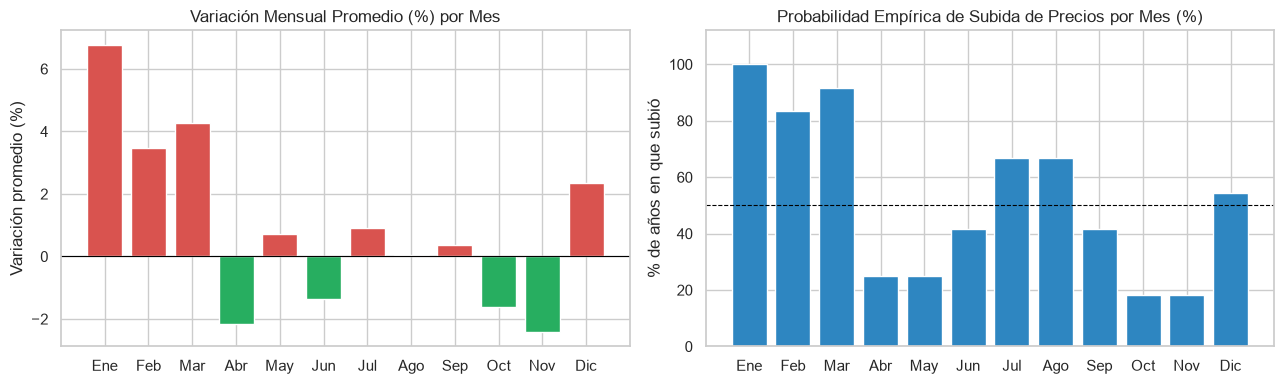

In [3]:
meses_lbl = ['Ene', 'Feb', 'Mar', 'Abr', 'May', 'Jun', 'Jul', 'Ago', 'Sep', 'Oct', 'Nov', 'Dic']
mes_stats = canasta.dropna(subset=['var_mensual_pct']).groupby('mes').agg(
    n_anios=('var_mensual_pct', 'count'),
    var_promedio_pct=('var_mensual_pct', 'mean'),
    var_mediana_pct=('var_mensual_pct', 'median'),
    prob_sube_pct=('var_mensual_pct', lambda s: (s > 0).mean() * 100),
    prob_alza_fuerte_pct=('alerta_encarecimiento', lambda s: s.mean() * 100),
).round(2)
mes_stats['mes_nombre'] = meses_lbl
display(mes_stats[['mes_nombre', 'n_anios', 'var_promedio_pct', 'var_mediana_pct', 'prob_sube_pct', 'prob_alza_fuerte_pct']])

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].bar(meses_lbl, mes_stats['var_promedio_pct'], color=['#d9534f' if v > 0 else '#27ae60' for v in mes_stats['var_promedio_pct']])
axes[0].axhline(0, color='black', lw=0.8)
axes[0].set_title('Variación Mensual Promedio (%) por Mes')
axes[0].set_ylabel('Variación promedio (%)')
axes[1].bar(meses_lbl, mes_stats['prob_sube_pct'], color='#2e86c1')
axes[1].axhline(50, color='black', ls='--', lw=0.8)
axes[1].set_title('Probabilidad Empírica de Subida de Precios por Mes (%)')
axes[1].set_ylabel('% de años en que subió')
axes[1].set_ylim(0, 112)
plt.tight_layout()
plt.show()

## Parte B: Procedimiento Paso a Paso – Prueba de Hipótesis para Diferencia de Dos Proporciones

Para cada pregunta evaluamos si la proporción de meses con **alza fuerte** ($\ge$ percentil 75 de variación mensual) difiere entre dos grupos:
1. **Proporciones muestrales:** $\hat{p}_1 = x_1 / n_1$ y $\hat{p}_2 = x_2 / n_2$.
2. **Proporción combinada (bajo $H_0$):** $\hat{p}_c = \frac{x_1 + x_2}{n_1 + n_2}$.
3. **Error estándar:** $SE = \sqrt{\hat{p}_c (1 - \hat{p}_c) \left(\frac{1}{n_1} + \frac{1}{n_2}\right)}$.
4. **Estadístico de prueba:** $z = \frac{\hat{p}_1 - \hat{p}_2}{SE}$.
5. **Regla de decisión ($\alpha = 0.05$):** Si $p\text{-valor} < 0.05$, **se rechaza $H_0$** (diferencia estadísticamente significativa).

In [4]:
def prueba_z_proporciones_detallada(nombre, x1, n1, x2, n2, bilateral=False, h0='p1 = p2', h1='p1 > p2'):
    p1 = x1 / n1
    p2 = x2 / n2
    p_comb = (x1 + x2) / (n1 + n2)
    se = np.sqrt(p_comb * (1 - p_comb) * (1 / n1 + 1 / n2))
    z = (p1 - p2) / se if se > 0 else 0.0
    p_val = 2 * (1 - stats.norm.cdf(abs(z))) if bilateral else (1 - stats.norm.cdf(z))
    decision = 'Se rechaza H0 (Significativa)' if p_val < 0.05 else 'No se rechaza H0'
    return {
        'Prueba': nombre,
        'H0 / H1': f'{h0} vs {h1}',
        'Grupo 1 (x1/n1)': f'{x1}/{n1} ({p1*100:.1f}%)',
        'Grupo 2 (x2/n2)': f'{x2}/{n2} ({p2*100:.1f}%)',
        'p_comb': round(p_comb, 4),
        'SE': round(se, 4),
        'z': round(float(z), 3),
        'p_valor': round(float(p_val), 5),
        'Decisión (α=0.05)': decision,
    }

resultados = []

# Referencia general: El Niño vs Neutro (Alimentos Frescos)
g_fase = canasta.groupby('enso_fase')['alerta_encarecimiento'].agg(['sum', 'count'])
resultados.append(prueba_z_proporciones_detallada(
    'Base: El Niño vs Neutro (Frescos)',
    int(g_fase.loc['El Niño', 'sum']), int(g_fase.loc['El Niño', 'count']),
    int(g_fase.loc['Neutro', 'sum']), int(g_fase.loc['Neutro', 'count']),
))

# P1: Umbral de intensidad (El Niño Fuerte >=1.5 vs Débil/Moderado 0.5 a <1.5)
solo_nino = canasta[canasta['enso_fase'] == 'El Niño']
fuerte = solo_nino[solo_nino['oni'] >= 1.5]['alerta_encarecimiento']
debil = solo_nino[solo_nino['oni'] < 1.5]['alerta_encarecimiento']
resultados.append(prueba_z_proporciones_detallada(
    'P1: El Niño Fuerte (>=1.5) vs Débil/Mod',
    int(fuerte.sum()), len(fuerte), int(debil.sum()), len(debil),
))

# P2: Doble golpe Estacionalidad x El Niño (Ene-Mar y Abr-Dic)
for lbl, mask in [('P2a: Ene-Mar (El Niño vs Neutro)', canasta['mes'].isin([1, 2, 3])),
                  ('P2b: Abr-Dic (El Niño vs Neutro)', ~canasta['mes'].isin([1, 2, 3]))]:
    sub_g = canasta[mask].groupby('enso_fase')['alerta_encarecimiento'].agg(['sum', 'count'])
    resultados.append(prueba_z_proporciones_detallada(
        lbl,
        int(sub_g.loc['El Niño', 'sum']), int(sub_g.loc['El Niño', 'count']),
        int(sub_g.loc['Neutro', 'sum']), int(sub_g.loc['Neutro', 'count']),
    ))

# P3: Mito El Niño vs La Niña (prueba bilateral)
resultados.append(prueba_z_proporciones_detallada(
    'P3: El Niño vs La Niña (Frescos)',
    int(g_fase.loc['El Niño', 'sum']), int(g_fase.loc['El Niño', 'count']),
    int(g_fase.loc['La Niña', 'sum']), int(g_fase.loc['La Niña', 'count']),
    bilateral=True, h0='p_Niño = p_Niña', h1='p_Niño != p_Niña',
))

# P4: Grupo de control natural (Procesados y Carnes en El Niño vs Neutro)
for cat in ['Procesados', 'Carnes']:
    sub = todos_grupos[todos_grupos['grupo'] == cat].copy()
    tot_m = sub['fecha'].nunique()
    core_p = sub.groupby('producto')['fecha'].nunique()
    core_p = core_p[core_p >= 0.9 * tot_m].index
    s = sub[sub['producto'].isin(core_p)].groupby(['fecha', 'enso_fase'], as_index=False)['indice_base100'].mean().sort_values('fecha')
    s['var_m'] = s['indice_base100'].pct_change() * 100
    u = s['var_m'].dropna().quantile(0.75)
    s['alerta'] = (s['var_m'] >= u).astype(int)
    gg = s.groupby('enso_fase')['alerta'].agg(['sum', 'count'])
    resultados.append(prueba_z_proporciones_detallada(
        f'P4 Control: {cat} (El Niño vs Neutro)',
        int(gg.loc['El Niño', 'sum']), int(gg.loc['El Niño', 'count']),
        int(gg.loc['Neutro', 'sum']), int(gg.loc['Neutro', 'count']),
    ))

tabla_hipotesis = pd.DataFrame(resultados)
display(tabla_hipotesis)

,Prueba,H0 / H1,Grupo 1 (x1/n1),Grupo 2 (x2/n2),p_comb,SE,z,p_valor,Decisión (α=0.05)
0,Base: El Niño vs Neutro (Frescos),p1 = p2 vs p1 > p2,18/49 (36.7%),6/62 (9.7%),0.2162,0.0787,3.439,0.00029,Se rechaza H0 (Significativa)
1,P1: El Niño Fuerte (>=1.5) vs Débil/Mod,p1 = p2 vs p1 > p2,10/17 (58.8%),8/32 (25.0%),0.3673,0.1447,2.338,0.00970,Se rechaza H0 (Significativa)
2,P2a: Ene-Mar (El Niño vs Neutro),p1 = p2 vs p1 > p2,9/15 (60.0%),3/11 (27.3%),0.4615,0.1979,1.654,0.04908,Se rechaza H0 (Significativa)
3,P2b: Abr-Dic (El Niño vs Neutro),p1 = p2 vs p1 > p2,9/34 (26.5%),3/51 (5.9%),0.1412,0.0771,2.671,0.00379,Se rechaza H0 (Significativa)
4,P3: El Niño vs La Niña (Frescos),p_Niño = p_Niña vs p_Niño != p_Niña,18/49 (36.7%),11/30 (36.7%),0.3671,0.1117,0.006,0.99514,No se rechaza H0
5,P4 Control: Procesados (El Niño vs Neutro),p1 = p2 vs p1 > p2,10/49 (20.4%),13/62 (21.0%),0.2072,0.0775,-0.072,0.52879,No se rechaza H0
6,P4 Control: Carnes (El Niño vs Neutro),p1 = p2 vs p1 > p2,9/49 (18.4%),15/62 (24.2%),0.2162,0.0787,-0.740,0.77048,No se rechaza H0


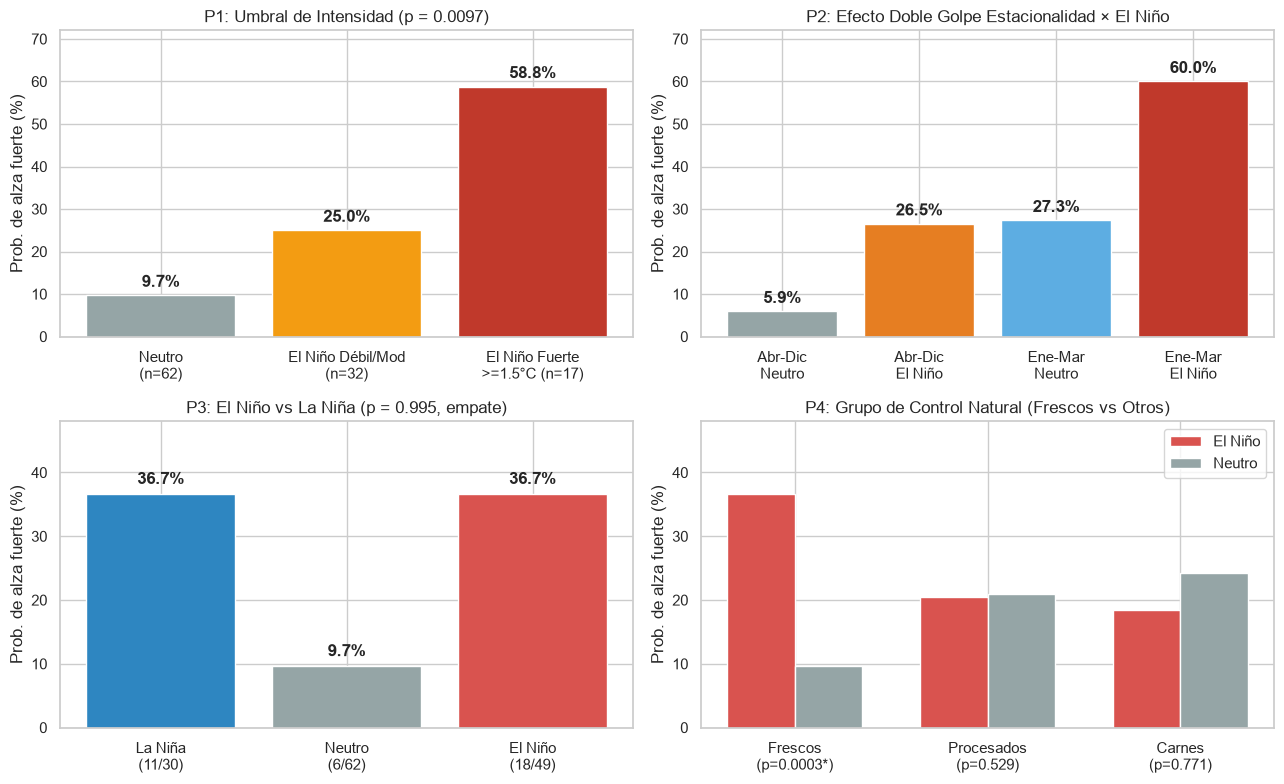

In [5]:
# Visualización resumen de las 4 preguntas no obvias
fig, axes = plt.subplots(2, 2, figsize=(13, 8))

# 1. Umbral de intensidad
axes[0, 0].bar(['Neutro\n(n=62)', 'El Niño Débil/Mod\n(n=32)', 'El Niño Fuerte\n>=1.5°C (n=17)'], [9.7, 25.0, 58.8], color=['#95a5a6', '#f39c12', '#c0392b'])
axes[0, 0].set_title('P1: Umbral de Intensidad (p = 0.0097)')
axes[0, 0].set_ylabel('Prob. de alza fuerte (%)')
axes[0, 0].set_ylim(0, 72)
for i, v in enumerate([9.7, 25.0, 58.8]):
    axes[0, 0].text(i, v + 2, f'{v:.1f}%', ha='center', fontweight='bold')

# 2. Doble golpe Estacionalidad x El Niño
axes[0, 1].bar(['Abr-Dic\nNeutro', 'Abr-Dic\nEl Niño', 'Ene-Mar\nNeutro', 'Ene-Mar\nEl Niño'], [5.9, 26.5, 27.3, 60.0], color=['#95a5a6', '#e67e22', '#5dade2', '#c0392b'])
axes[0, 1].set_title('P2: Efecto Doble Golpe Estacionalidad × El Niño')
axes[0, 1].set_ylabel('Prob. de alza fuerte (%)')
axes[0, 1].set_ylim(0, 72)
for i, v in enumerate([5.9, 26.5, 27.3, 60.0]):
    axes[0, 1].text(i, v + 2, f'{v:.1f}%', ha='center', fontweight='bold')

# 3. El Niño vs La Niña
axes[1, 0].bar(['La Niña\n(11/30)', 'Neutro\n(6/62)', 'El Niño\n(18/49)'], [36.7, 9.7, 36.7], color=['#2e86c1', '#95a5a6', '#d9534f'])
axes[1, 0].set_title('P3: El Niño vs La Niña (p = 0.995, empate)')
axes[1, 0].set_ylabel('Prob. de alza fuerte (%)')
axes[1, 0].set_ylim(0, 48)
for i, v in enumerate([36.7, 9.7, 36.7]):
    axes[1, 0].text(i, v + 1.5, f'{v:.1f}%', ha='center', fontweight='bold')

# 4. Grupo de control: Frescos vs Procesados vs Carnes (El Niño vs Neutro)
x = np.arange(3)
w = 0.35
axes[1, 1].bar(x - w/2, [36.7, 20.4, 18.4], w, label='El Niño', color='#d9534f')
axes[1, 1].bar(x + w/2, [9.7, 21.0, 24.2], w, label='Neutro', color='#95a5a6')
axes[1, 1].set_xticks(x)
axes[1, 1].set_xticklabels(['Frescos\n(p=0.0003*)', 'Procesados\n(p=0.529)', 'Carnes\n(p=0.771)'])
axes[1, 1].set_title('P4: Grupo de Control Natural (Frescos vs Otros)')
axes[1, 1].set_ylabel('Prob. de alza fuerte (%)')
axes[1, 1].set_ylim(0, 48)
axes[1, 1].legend()

plt.tight_layout()
plt.show()

## Conclusiones del Análisis (Observación vs. Causalidad)

- **P1 (Umbral de intensidad):** El Niño Fuerte ($\ge +1.5\,^\circ\text{C}$) más que duplica la probabilidad de alzas fuertes (`58.8 %` vs. `25.0 %` en Débil/Moderado, $z=2.338, p=0.0097$).
- **P2 (Doble golpe):** Coincidir **Ene–Mar + El Niño** eleva la probabilidad al **60.0 %** (10× frente al **5.9 %** de Abr–Dic Neutro).
- **P3 (Mito refutado):** No hay diferencia entre El Niño (`36.7 %`) y La Niña (`36.7 %`, $p=0.995$): ambos extremos climáticos golpean con igual severidad al Cauca.
- **P4 (Control natural):** Mientras los **Alimentos Frescos** muestran una diferencia altamente significativa ($p=0.00029$), **Procesados** ($p=0.529$) y **Carnes** ($p=0.771$) no cambian significativamente en El Niño, confirmando que el fenómeno se concentra en la producción agrícola directa.
- **Rigor causal:** Estas pruebas confirman asociaciones estadísticas robustas, pero no excluyen factores externos (bloqueos en la Vía Panamericana, fletes, fertilizantes e inflación general).